# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [21]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [22]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [23]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [24]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [25]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [26]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [27]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [28]:
print("""
LabelEncoder convierte cada categoría en un número entero.
Por ejemplo: Masculino=0, Femenino=1.

OneHotEncoder crea una columna para cada categoría y utiliza
valores 0 y 1 para indicar la presencia de cada una.

OneHotEncoder evita que el modelo interprete un orden entre las categorías,
mientras que LabelEncoder puede introducir una relación numérica artificial.
""")


LabelEncoder convierte cada categoría en un número entero.
Por ejemplo: Masculino=0, Femenino=1.

OneHotEncoder crea una columna para cada categoría y utiliza
valores 0 y 1 para indicar la presencia de cada una.

OneHotEncoder evita que el modelo interprete un orden entre las categorías,
mientras que LabelEncoder puede introducir una relación numérica artificial.



### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

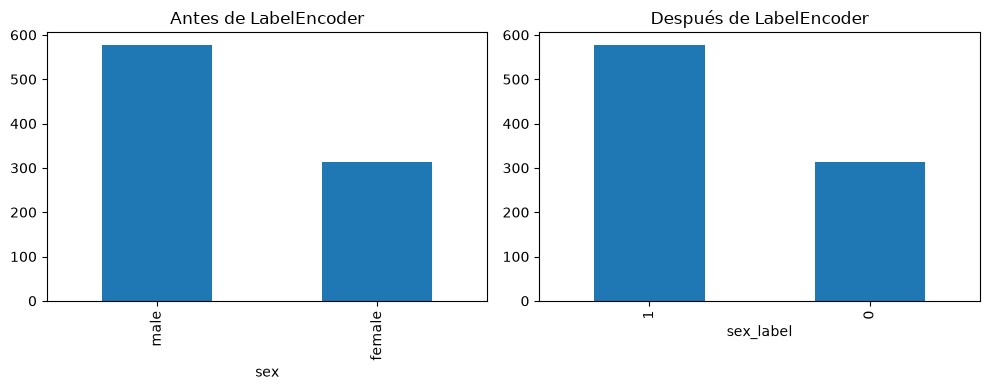

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10,4))

data['sex'].value_counts().plot(
    kind='bar',
    ax=ax[0],
    title='Antes de LabelEncoder'
)

data['sex_label'].value_counts().plot(
    kind='bar',
    ax=ax[1],
    title='Después de LabelEncoder'
)

plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [30]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

encoder = OneHotEncoder(sparse_output=False)

encoded = encoder.fit_transform(data[['class']])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(['class'])
)

print(encoded_df.head())

print("""
Ventajas de OneHotEncoder:
- No introduce un orden artificial entre categorías.
- Es adecuado para variables nominales.
- Suele mejorar el desempeño de muchos modelos de aprendizaje automático.
""")

   class_First  class_Second  class_Third
0          0.0           0.0          1.0
1          1.0           0.0          0.0
2          0.0           0.0          1.0
3          1.0           0.0          0.0
4          0.0           0.0          1.0

Ventajas de OneHotEncoder:
- No introduce un orden artificial entre categorías.
- Es adecuado para variables nominales.
- Suele mejorar el desempeño de muchos modelos de aprendizaje automático.



### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [31]:
print("""
Para la mayoría de los modelos elegiría OneHotEncoder para las variables
categóricas nominales porque evita asignar valores numéricos que puedan
ser interpretados como una relación de orden. Esto permite representar
cada categoría de manera independiente y reduce sesgos en el entrenamiento.
""")


Para la mayoría de los modelos elegiría OneHotEncoder para las variables
categóricas nominales porque evita asignar valores numéricos que puedan
ser interpretados como una relación de orden. Esto permite representar
cada categoría de manera independiente y reduce sesgos en el entrenamiento.

